Importações

In [20]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt

Funções

In [21]:
def pesos(n_entradas, intervalo=(-0.5, 0.5)):
    pesos = np.random.uniform(intervalo[0], intervalo[1], n_entradas + 1)
    return pesos

def degrau(z):
    return 1 if z>=0 else 0

def prever(exemplo, pesos):
    z = np.dot(exemplo, pesos[1:]) + pesos[0] 
    return degrau(z)

def treinar_perceptron(X, Y, taxa_aprendizado=0.1, pesos_iniciais=None):
    num_amostras, num_entradas = X.shape

    if pesos_iniciais is None:
        pesos = pesos(num_entradas)
    else:
        pesos = pesos_iniciais.copy()

    epocas = 0
    total_ajustes = 0
    convergiu = False

    while not convergiu:
        erros_na_epoca = 0
        epocas += 1

        for i in range(num_amostras):
            x_i = X[i]
            y_d = Y[i]

            z = np.dot(x_i, pesos[1:]) + pesos[0]
            y_chapeu = degrau(z)

            erro = y_d - y_chapeu

            if erro != 0:
                pesos[0] += taxa_aprendizado * erro         # ATUALIZA BIAS
                pesos[1:] += taxa_aprendizado * erro * x_i  # ATUALIZA PESOS

                total_ajustes += 1
                erros_na_epoca += 1

       
        if erros_na_epoca == 0:
            convergiu = True

    return pesos, epocas, total_ajustes


COLETA DOS DADOS

In [22]:

dados = np.load('dados/dataAll20262.txt', allow_pickle=True)

print("Dados carregados com sucesso! Formato:", dados.shape)


if dados.ndim == 3:
    dados = dados.squeeze(axis=1) # Transforma (m, 1, 3) em (m, 3)

X = dados[:, :2]  
Y = dados[:, 2]   

Dados carregados com sucesso! Formato: (1000, 1, 3)


TREINAMENTO

Vetor inicial de pesos (incluindo bias): [-0.12545988  0.45071431  0.23199394]

--- RESULTADOS DO TREINAMENTO ---
Número de épocas até a convergência: 3
Número total de ajustes no vetor de pesos: 42
Pesos finais otimizados: [  -0.52545988   77.49164736 -385.93744796]


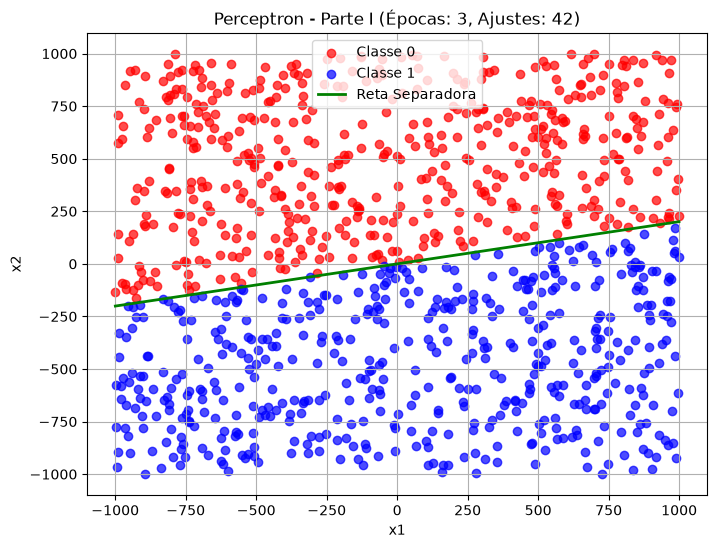

In [23]:
TAXA_APRENDIZADO = 0.1


np.random.seed(42) #SEMENTE DE ALEATORIEDADE 
pesos_iniciais = np.random.uniform(-0.5, 0.5, X.shape[1] + 1)

print("Vetor inicial de pesos (incluindo bias):", pesos_iniciais)

# TREINAMENTO
pesos_finais, total_epocas, total_ajustes = treinar_perceptron(X, Y, TAXA_APRENDIZADO, pesos_iniciais)

print(f"\n--- RESULTADOS DO TREINAMENTO ---")
print(f"Número de épocas até a convergência: {total_epocas}")
print(f"Número total de ajustes no vetor de pesos: {total_ajustes}")
print(f"Pesos finais otimizados: {pesos_finais}")


# CLASSES
classe_0 = X[Y == 0]
classe_1 = X[Y == 1]

plt.figure(figsize=(8, 6))

# DEFININDO PADRÃO E CORES
plt.scatter(classe_0[:, 0], classe_0[:, 1], color='red', label='Classe 0', alpha=0.7)
plt.scatter(classe_1[:, 0], classe_1[:, 1], color='blue', label='Classe 1', alpha=0.7)

# COEFICIENTES DA RETA SEPARADORA
b = pesos_finais[0]
w1 = pesos_finais[1]
w2 = pesos_finais[2]

# LIMITE DO EIXO X
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x1_valores = np.array([x1_min, x1_max])

# CALCULANDO OS VALORES DE x2 PARA A RETA SEPARADORA
if w2 != 0:
    x2_valores = (-w1 * x1_valores - b) / w2
    plt.plot(x1_valores, x2_valores, color='green', linewidth=2, label='Reta Separadora')

plt.xlabel('x1')
plt.ylabel('x2')
plt.title(f'Perceptron - Parte I (Épocas: {total_epocas}, Ajustes: {total_ajustes})')
plt.legend()
plt.grid(True)
plt.show()